### ELO328 - Procesamiento Digital de Imágenes
# Clase 3: Filtros digitales de suavizado
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Filtros digitales

- **Suavizar la imagen:** reducir las variaciones de intensidad entre píxeles vecinos.
- **Eliminar ruido:** modificar aquellos píxeles cuyo nivel de intensidad es muy diferente al de sus vecinos.
- **Realzar la imagen:** aumentar las variaciones de intensidad, allí donde se producen.
- **Detectar bordes:** detectar aquellos píxeles donde se produce un cambio brusco en la función intensidad.

# Ruido

Es información no deseada que contamina la imagen.

$$ g(x,y)=f(x,y)+r(x,y) $$

El origen puede estar tanto en el proceso de adquisición de la imagen (errores en los sensores), como en el de transmisión (debido a interferencias en el canal de transmisión).

Existen distintos modelos de ruido, según las funciones de densidad de probabilidad que sigan sus intensidades $r(x,y)$.

# Ruido Gaussiano (o normal)

<div align="center">
    <img src="img/gauss.jpg" alt="" width="20%" align="right" />
</div>

Modela el ruido producido por los circuitos electrónicos o ruido de los sensores por falta de iluminación y/o altas temperaturas. La intensidad de los píxeles se ve afectada de acuerdo a una distribución normal (o distribución de Gauss).

In [1]:
# Required: seaborn, skimage, scipy, numpy, matplotlib, interact, fixed
# pip install skimage

In [2]:
import skimage
from skimage.io import imread
from skimage.util import random_noise
from scipy import misc
from scipy.signal import convolve2d
from scipy import ndimage
from scipy.ndimage import median_filter
from matplotlib import pyplot as plt
from ipywidgets import interact, fixed
import numpy as np
import seaborn as sns

In [3]:
lena = imread("img/lena.jpg")

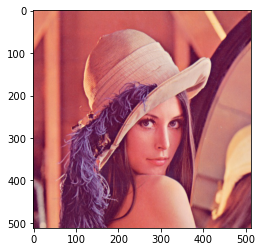

In [4]:
plt.imshow(lena)
plt.show()

In [5]:
def ruido_gaussiano(imagen, varianza=0.05, output_return=True, plot=True):
    noisy = random_noise(image = imagen, mode='gaussian', var=varianza)
    out = np.interp(noisy, (noisy.min(), noisy.max()), (0, 255)).astype('uint8')
    if plot:
        fig = plt.figure(figsize=(13, 5))
        ax1 = fig.add_subplot(121) 
        ax2 = fig.add_subplot(122) 
        ax1.set_title("Imagen Original")
        ax2.set_title(f"Ruido Gaussiano con σ²={varianza}")  
        ax1.imshow(imagen)
        ax2.imshow(out)
        plt.show()    
    if output_return:
        return out

In [6]:
interact(ruido_gaussiano, imagen=fixed(lena), varianza=(0,1,0.05), output_return=False);

interactive(children=(FloatSlider(value=0.05, description='varianza', max=1.0, step=0.05), Checkbox(value=Fals…

# Ruido impulsivo (sal y pimienta)

Se caracteriza principalmente por cubrir de forma dispersa toda la imagen con una serie de píxeles blancos y negros.

Este tipo de ruido suele producirse cuando la señal de la imagen es afectada por intensas y repentinas perturbaciones o impulsos.

In [7]:
def ruido_sal_pimienta(imagen, potencia = 0.05, ratio=0.5, output_return=True, plot=True):  
    noisy = random_noise(image = imagen, mode = "s&p", amount = potencia, salt_vs_pepper=ratio)
    out = np.interp(noisy, (noisy.min(), noisy.max()), (0, 255)).astype('uint8')
    if plot:
        fig = plt.figure(figsize=(13, 5))
        ax1 = fig.add_subplot(121) 
        ax2 = fig.add_subplot(122) 
        ax1.set_title("Imagen Original")
        ax2.set_title(f"Ruido Impulsivo con {round(ratio*100)}% sal y {round((1-ratio)*100)}% pimienta")  
        ax1.imshow(imagen)
        ax2.imshow(out)
        plt.show()
    if output_return:
        return out

In [8]:
interact(ruido_sal_pimienta, imagen=fixed(lena), potencia=(0,1,0.05), ratio=(0,1,0.05), output_return=False);

interactive(children=(FloatSlider(value=0.05, description='potencia', max=1.0, step=0.05), FloatSlider(value=0…

# Enfoques

Los filtros se pueden clasificar en:

- Filtros en el dominio del espacio: trabajan directamente sobre los píxeles de la imagen.
    - Suavizado: difuminado (blurring) o eliminación de ruido.
        - Filtros lineales: media, gaussiano.
        - Filros no lineales: máximo, mínimo, mediana.
    - Realce: detección de lados o bordes.
- Filtros en el dominio de la frecuencia: las operaciones se llevan a cabo en la transformada de Fourier de la imagen. Pueden eliminar altas o bajas frecuencias de la imagen, lo que se traduce en suavizar la imagen, o bien, realzar o detectar bordes.

# Filtros en el dominio del espacio

Las operaciones espaciales de filtrado se definen en un entorno de vecindad del punto a transformar $(x,y)$.

<div align="center">
    <img src="img/dominioespacio.png" alt="" width="30%" align="center" />
</div>

Los filtros en el dominio del espacio pueden clasificarse en:
1. Filtros lineales.
2. Filtros no lineales.

# Filtros lineales

Se aplica un **Filtro** (Kernel, Máscara, Ventana), sobre los píxeles de una imagen $f(x,y)$:

<div align="center">
    <img src="img/kernel.png" alt="" width="30%" align="left" />
    <img src="img/pixeles.png" alt="" width="25%" align="right" />
</div>

# Filtros lineales

Dada una imagen $f(x,y)$ y un filtro $w(x,y)$, la imagen resultante $g(x,y)$ consiste en realizar la operación:

$$ g(x,y) = \sum_{s=-a}^{a} \sum_{t=-b}^{b} w(s,t) f(x+s, y+t), $$

asumiendo que $m=2a+1$ y $n=2b+1$ para un kernel de tamaño $m \times n$, con $a$ y $b$ enteros no negativos.

# Kernel

Es una matriz de coeficientes:

- El entorno del punto $(x,y)$ que se considera en la imagen para obtener $g(x,y)$ está determinado por el tamaño y forma de la máscara.
- El tipo de filtrado está determinado por el contenido de la máscara.

<div align="center">
    <img src="img/coefficients.png" alt="" width="25%" align="center" />
</div>

# Convolución

Es un operador matemático que transforma dos funciones en una tercera función, que en cierto sentido, representa la magnitud en la que se superponen la primera función y una versión trasladada de la segunda.

<div align="center">
    <img src="img/convolution.png" alt="" width="30%" align="center" />
</div>

# Ejemplo de convolución


<div align="center">
    <img src="img/convolution_example.jpeg" alt="" width="50%" align="center" />
</div>

# Parámetros básicos de una convolución

- Dimensiones del filtro: 2D para imágenes.
- Tamaño del filtro: Variable, generalmente tamaño impar como 3x3 o 5x5.
- Stride: paso para deslizar la ventana de convolución. Generalmente igual a 1.
- Padding: se agregan celdas en los bordes de la imagen de entrada.

<div align="center">
    <img src="img/padding_full.png" alt="" width="40%" align="center" />
</div>
Ejemplo de padding en modo "full".

# Métodos de padding


- ‘reflect’ (d c b a | a b c d | d c b a)

- ‘constant’ (k k k k | a b c d | k k k k)

- ‘nearest’ (a a a a | a b c d | d d d d)

- ‘mirror’ (d c b | a b c d | c b a)

- ‘wrap’ (a b c d | a b c d | a b c d)

# Filtro de la media

Se visita cada píxel de la imagen y se reemplaza por la media de los píxeles vecinos. Se puede operar mediante convolución con una máscara determinada.

Desventajas:

- Es bastante sensible a cambios locales.
- Puede crear nuevas intensidades que no aparecían en la imagen.

# Ejemplo filtro de la media

<div align="center">
    <img src="img/media.png" alt="" width="60%" align="center" />
</div>

Vecindario: 30, 35, 37, 40, 37, 43, 40, 43, 42

Valor media: (30 + 35 + 37 + 40 + 37 + 43 + 40 + 43 + 42)/9 = 39.

# Filtro de la media en Python

In [9]:
X = [[0,3,3], [2,3,3], [1,2,1]]

In [10]:
mask = [[1/4,1/4],[1/4,1/4]]

Para realizar la convolución se utilizará la función `scipy.signal.convolve2d`.

**Parámetros en `scipy.signal.convolve2d`:**

- `mode`:
    - `full` (Default): genera output con la convolución lineal discreta completa del input (mayor tamaño).
    - `valid`: genera output sin utilizar padding (menor tamaño).
    - `same`: genera output con mismas dimensiones que input.
- `boundary`:
    - `fill` (Default): rellena padding con `fillvalue`.
    - `wrap`: circular.
    - `symm`: simétrico.
- `fillvalue`: Valor numérico para padding. El valor predeterminado es 0.

In [11]:
def show_mean_filter(figure, size=2, mode="same", boundary="fill", fillvalue=0):
    fig1, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(15,5))
    sns.heatmap(figure, annot=True, cbar=False, xticklabels=False, yticklabels=False, cmap='binary',
                linewidths=1, linecolor='k', annot_kws={"size": 16, 'fontweight': 'bold'}, ax=ax1)
    ax1.set_title("Input")
    mask = np.full((size,size), 1/(size**2))
    sns.heatmap(mask, annot=True, cbar=False, xticklabels=False, yticklabels=False, cmap='binary',
                linewidths=1, linecolor='k', annot_kws={"size": 16, 'fontweight': 'bold'}, ax=ax2)
    ax2.set_title("Mask")    
    g = convolve2d(figure,mask,mode=mode,boundary=boundary,fillvalue=fillvalue)
    sns.heatmap(g, annot=True, cbar=False, xticklabels=False, yticklabels=False, cmap='binary',
                linewidths=1, linecolor='k', annot_kws={"size": 16, 'fontweight': 'bold'}, ax=ax3)
    ax3.set_title("Output")

In [12]:
interact(show_mean_filter, figure=fixed(X), size=(2,3), mode=["full","valid","same"], boundary=["fill","wrap","symm"], fillvalue=range(10));

interactive(children=(IntSlider(value=2, description='size', max=3, min=2), Dropdown(description='mode', index…

In [13]:
def filtro_media(imagen, tamaño=1, mode="same", boundary="fill", fillvalue=0, output_return=True, plot=True):
    ims = []
    mask = np.full((tamaño,tamaño), 1/(tamaño**2))
    for d in range(3):
        im_conv_d = convolve2d(imagen[:,:,d], mask, mode=mode, boundary=boundary, fillvalue=fillvalue)
        ims.append(im_conv_d)
    im_conv = np.stack(ims, axis=2).astype("uint8")
    if plot:
        fig = plt.figure(figsize=(13, 5))
        ax1 = fig.add_subplot(121) 
        ax2 = fig.add_subplot(122) 
        ax1.set_title("Imagen Original")
        ax2.set_title(f"Filtro de la media con tamaño {tamaño}")  
        ax1.imshow(imagen)
        ax2.imshow(im_conv)
        plt.show()
    if output_return:
        return im_conv

In [14]:
lena_gaussiana = ruido_gaussiano(lena, varianza=0.2, plot=False)
interact(filtro_media, imagen=fixed(lena_gaussiana), mode=fixed('same'), boundary=fixed("fill"), fillvalue=fixed(0), tamaño=range(1,50), output_return=False);

interactive(children=(Dropdown(description='tamaño', options=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 1…

In [15]:
lena_sal = ruido_sal_pimienta(lena, potencia=0.3, ratio=0.9, plot=False)
interact(filtro_media, imagen=fixed(lena_sal), mode=fixed('same'), boundary=fixed("fill"), fillvalue=fixed(0), tamaño=range(1,50), output_return=False);

interactive(children=(Dropdown(description='tamaño', options=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 1…

In [16]:
lena_pimienta = ruido_sal_pimienta(lena, potencia=0.3, ratio=0.1, plot=False)
interact(filtro_media, imagen=fixed(lena_pimienta), mode=fixed('same'), boundary=fixed("fill"), fillvalue=fixed(0), tamaño=range(1,50), output_return=False);

interactive(children=(Dropdown(description='tamaño', options=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 1…

# Filtro Gaussiano

El filtro Gaussiano se usa para emborronar imágenes y eliminar ruido. Es similar al filtro de media, pero se usa una máscara diferente, modelizando la función gaussiana:

$$ G(x) = \frac{1}{2\pi\sigma^2} e^{- { \frac{x^2+y^2}{ 2 \sigma^2} } } $$

<div align="center">
    <img src="img/gaussian.jpg" alt="" width="60%" align="center" />
</div>

In [17]:
def filtro_gaussiano(imagen, tamaño=1, sigma=1, mode="same", boundary="fill", fillvalue=0, output_return=True, plot=True):
    nn = int((tamaño-1)/2)
    a = np.asarray([[x**2 + y**2 for x in range(-nn,nn+1)] for y in range(-nn,nn+1)])        
    mask = np.exp(-a/(2*sigma**2))
    mask /= np.sum(mask)
    ims = []
    for d in range(3):
        im_conv_d = convolve2d(imagen[:,:,d], mask, mode=mode, boundary=boundary, fillvalue=fillvalue)
        ims.append(im_conv_d)
    im_conv = np.stack(ims, axis=2).astype("uint8")
    if plot:
        fig = plt.figure(figsize=(13, 5))
        ax1 = fig.add_subplot(121) 
        ax2 = fig.add_subplot(122) 
        ax1.set_title("Imagen Original")
        ax2.set_title(f"Filtro Gaussiano con tamaño {tamaño} y σ={sigma}")  
        ax1.imshow(imagen)
        ax2.imshow(im_conv)    
        plt.show()
    if output_return:
        return im_conv

In [18]:
interact(filtro_gaussiano, imagen=fixed(lena_gaussiana), tamaño=range(1,20), sigma=[0.25,0.5,0.75,1,2,5,10], mode=fixed("same"), boundary=fixed("fill"), fillvalue=fixed(0), output_return=False);

interactive(children=(Dropdown(description='tamaño', options=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 1…

# Filtros no lineales

**Filtros estadísticos de orden:** funcionan ordenando los valores en la vecindad de cada punto de menor a mayor, y obteniendo algún valor a partir de la lista ordenada.

- Mínimo: selecciona el valor más pequeño.
- Máximo: selecciona el valor más alto.
- Mediana: selecciona el valor en la posición intermedia.

# Filtro del máximo

Selecciona el mayor valor dentro de una ventana ordenada de valores de nivel de gris.

- Ventaja: Elimina el ruido pimienta (píxeles negros).
- Inconvenientes:
    - Sólo funciona cuando el ruido es exclusivamente tipo pimienta.
    - Tiende a aclarar la imagen.

# Ejemplo filtro del máximo

<div align="center">
    <img src="img/maximo.png" alt="" width="60%" align="center" />
</div>

# Filtro del mínimo

Selecciona el menor valor dentro de una ventana ordenada de valores de nivel de gris.

- Ventaja: Elimina el ruido sal (píxeles blancos).
- Inconvenientes:
    - Sólo funciona cuando el ruido es exclusivamente tipo sal.
    - Tiende a oscurecer la imagen.

# Ejemplo filtro del mínimo

<div align="center">
    <img src="img/minimo.png" alt="" width="60%" align="center" />
</div>

# Ejemplo filtro del máximo y del mínimo en Python

Para mostrar el filtro del máximo y del mínimo se utilizarán las funciones `scipy.ndimage.maximum_filter` y `scipy.ndimage.minimum_filter`.

**Parámetros más importantes:**

- `mode`:
    - `‘reflect’` (d c b a | a b c d | d c b a)
    - `‘constant’` (k k k k | a b c d | k k k k)
    - `‘nearest’` (a a a a | a b c d | d d d d)
    - `‘mirror’` (d c b | a b c d | c b a)
    - `‘wrap’` (a b c d | a b c d | a b c d)
- `cval`: Valor numérico para padding. El valor predeterminado es 0.

In [19]:
def comparison_max_min(figure, size, mode="constant", cval=0):
    fig1, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(15,5))
    sns.heatmap(figure, annot=True, cbar=False, xticklabels=False, yticklabels=False, cmap='binary',
                linewidths=1, linecolor='k', annot_kws={"size": 16, 'fontweight': 'bold'}, ax=ax1)
    ax1.set_title("Input")
    maximum = ndimage.maximum_filter(figure, size=size, mode=mode, cval=cval)
    sns.heatmap(maximum, annot=True, cbar=False, xticklabels=False, yticklabels=False, cmap='binary',
                linewidths=1, linecolor='k', annot_kws={"size": 16, 'fontweight': 'bold'}, ax=ax2)
    ax2.set_title("maximum")
    minimum = ndimage.minimum_filter(figure, size=size, mode=mode, cval=cval)
    sns.heatmap(minimum, annot=True, cbar=False, xticklabels=False, yticklabels=False, cmap='binary',
                linewidths=1, linecolor='k', annot_kws={"size": 16, 'fontweight': 'bold'}, ax=ax3)
    ax3.set_title("minimum")

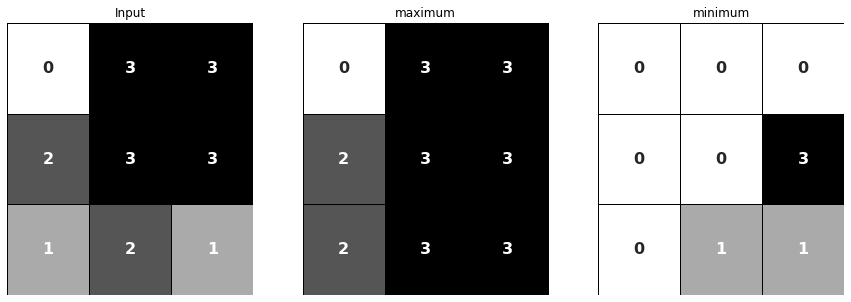

In [20]:
comparison_max_min(X, size=2, mode="constant", cval=0)

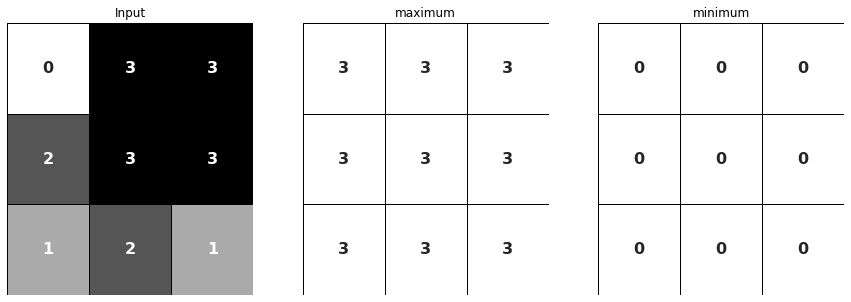

In [21]:
comparison_max_min(X, size=3, mode="constant", cval=0)

In [22]:
def filtros_max_min(imagen, tamaño=3, output_return=True, plot=True):   
    maximum = ndimage.maximum_filter(imagen, size=tamaño)
    minimum = ndimage.minimum_filter(imagen, size=tamaño)  
    if plot:
        fig = plt.figure(figsize=(15,10))
        ax1 = fig.add_subplot(131) 
        ax2 = fig.add_subplot(132)  
        ax3 = fig.add_subplot(133) 
        ax1.set_title("Imagen Original")            
        ax2.set_title(f"Filtro del máximo con tamaño {tamaño}")
        ax3.set_title(f"Filtro del mínimo con tamaño {tamaño}")
        ax1.imshow(imagen)
        ax2.imshow(maximum)
        ax3.imshow(minimum)    
        plt.show()
    if output_return:
        return maximum,minimum

In [23]:
interact(filtros_max_min, imagen=fixed(lena), tamaño=(1,50), output_return=False);

interactive(children=(IntSlider(value=3, description='tamaño', max=50, min=1), Checkbox(value=False, descripti…

In [24]:
interact(filtros_max_min, imagen=fixed(lena_sal), tamaño=(1,5), output_return=False);

interactive(children=(IntSlider(value=3, description='tamaño', max=5, min=1), Checkbox(value=False, descriptio…

In [25]:
interact(filtros_max_min, imagen=fixed(ruido_sal_pimienta(lena, potencia=0.3, ratio=1, plot=False)), tamaño=(1,5), output_return=False);

interactive(children=(IntSlider(value=3, description='tamaño', max=5, min=1), Checkbox(value=False, descriptio…

In [26]:
interact(filtros_max_min, imagen=fixed(lena_pimienta), tamaño=fixed((4,1,0)), output_return=False);

interactive(children=(Checkbox(value=False, description='output_return'), Checkbox(value=True, description='pl…

In [27]:
interact(filtros_max_min, imagen=fixed(ruido_sal_pimienta(lena, potencia=0.3, ratio=0, plot=False)), tamaño=fixed((4,1,0)), output_return=False);

interactive(children=(Checkbox(value=False, description='output_return'), Checkbox(value=True, description='pl…

# Filtro de la mediana

Se suele usar para eliminar ruido en la imagen.

Se visita cada píxel de la imagen y se reemplaza por la mediana de los píxeles vecinos. La mediana se calcula ordenando los valores de los pixeles vecinos en orden y seleccionado el que queda en medio.

**Desventaja:** Este filtro no es lineal. Dadas dos imágenes A y B, mediana(A+B)≠mediana(A)+mediana(B)

**Ventaja:** Da muy buenos resultados en caso de ruido sal y pimienta.

# Ejemplo filtro de la mediana

<div align="center">
    <img src="img/mediana.png" alt="" width="60%" align="center" />
</div>

Vecindario ordenado: 115, 119, 120, 123, **124**, 125, 126, 127, 150.

Valor mediana: 124.

In [28]:
def filtro_mediana(imagen, tamaño=1, output_return=True, plot=True):   
    ims = []
    for d in range(3):
        im_conv_d = median_filter(imagen[:,:,d], size=(tamaño,tamaño))
        ims.append(im_conv_d)
    im_conv = np.stack(ims, axis=2).astype("uint8")
    if plot:
        fig = plt.figure(figsize=(13, 5))
        ax1 = fig.add_subplot(121) 
        ax2 = fig.add_subplot(122) 
        ax1.set_title("Imagen Original")
        ax2.set_title(f"Filtro de la mediana con tamaño {tamaño}")  
        ax1.imshow(imagen)
        ax2.imshow(im_conv)    
        plt.show()
    if output_return:
        return im_conv

In [29]:
interact(filtro_mediana, imagen=fixed(lena_gaussiana), tamaño=(1,20), output_return=False);

interactive(children=(IntSlider(value=1, description='tamaño', max=20, min=1), Checkbox(value=False, descripti…

In [30]:
interact(filtro_mediana, imagen=fixed(lena_sal), tamaño=(1,20), output_return=False);

interactive(children=(IntSlider(value=1, description='tamaño', max=20, min=1), Checkbox(value=False, descripti…

In [31]:
interact(filtro_mediana, imagen=fixed(lena_pimienta), tamaño=(1,20), output_return=False);

interactive(children=(IntSlider(value=1, description='tamaño', max=20, min=1), Checkbox(value=False, descripti…